# Machine Learning in Python - Project 

Due Friday, December 4th 2026, by 4 pm.

**Alice Miller, Emma Crawford, Nina Beadnell, Maciek Romanowski**

## Setup

In [142]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

# Clustering modules
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_samples
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.decomposition import PCA

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak"
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [99]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")

# Introduction

Flooding poses a significant risk to communities across Scotland, with approximately 400,000 homes, businesses and vital services located in areas at medium risk of flooding, according to the National Flood Risk Assessment (NFRA) 2025 report [[1]](#ref1). Early warning of rising river levels gives local authorities and emergency services time to prepare, so understanding how rivers behave and when they are likely to flood is of considerable practical value [Nina's reference].

This report analyses daily river-level records from 392 water-level monitoring stations across 35 counties in Scotland, covering the period from 2014 to 2026. For each station, the data provide its name, ID, location (county, latitude and longitude) and daily mean, minimum and maximum water levels in metres. Before modelling, we examine the data for missing observations and outliers and account for differences in the periods over which individual stations were active. From the cleaned data, we construct features that characterise water-level behaviour, such as variability, seasonality, within-day fluctuations and autocorrelation.

Using supervised and unsupervised machine learning techniques, we aim to identify meaningful patterns in river behaviour and investigate the potential for predicting flood events. Two objectives are considered: one concerning the overall behaviour of water levels in Scottish rivers and the other concerning the prediction of flood events on a given day. The clustering task aims to identify groups of monitoring stations exhibiting similar water-level behaviour, allowing us to better understand the different characteristics of Scottish rivers. The classification task, on the other hand, aims to predict flood events based on observations from the preceding seven days. Together, these tasks allow us to investigate both the general characteristics of rivers and the possibility of anticipating extreme water-level events using historical observations alone.

First, we consider clustering, an unsupervised machine learning task in which, based on the constructed features, we aim to group together stations exhibiting similar properties. Clustering allows us to identify patterns and intrinsic relationships within the dataset. We implement K-means with K-means++ initialisation and analyse its performance. Our final clustering solution distinguishes between three groups of stations: those exhibiting tidal-like behaviour capturing most of the stations that record tidal observations, those characterised by relatively stable water levels and those exhibiting greater typical variability and more pronounced seasonal variations. Interestingly, the relatively stable stations exhibit more extreme high-water observations relative to their typical variability.

Second, we investigate whether a flood event can be accurately predicted from recent river behaviour. We define a flood event as an observation with an exceptionally high maximum water level relative to the historical observations at a given station. We then build a classification model to predict whether a flood event will occur based on measurements from the preceding seven days, considering features such as recent maximum water levels, their mean and variability. We investigate various classification models and assess their performance against a persistence baseline, which predicts a flood event if one occurred on the preceding day. Our final model is based on logistic regression, which we explore in detail in this report.

The two analyses, while independent of each other, provide complementary insights. The clustering reveals different patterns of river behaviour and may help identify stations that could benefit from different monitoring strategies, while the classification model and the features it relies on provide insight into which recent conditions might indicate an upcoming flood event. Through these analyses, we aim to provide insights that could support government agencies such as the Scottish Environment Protection Agency (SEPA) in developing more effective river monitoring and flood forecasting strategies.

The remainder of this report is organised as follows. We first present the exploratory data analysis (EDA), which motivates our data preprocessing decisions. We then discuss feature engineering and construct separate feature matrices for the clustering and classification tasks. Finally, we present our model fitting and tuning procedures, before interpreting the results and discussing the practical implications, reliability and limitations of our models.

# Exploratory Data Analysis and Feature Engineering

## Exploratory Data Analysis

Initial investigation of the data, as illustrated in the heatmap "Missing water-level observations across stations" below, indicates that a significant proportion of the data is missing (30.64%). This may be due to individual observations not being made, monitoring stations being decommissioned or stations not yet having begun recording.

From the heatmap, we can see that almost no stations have recorded observations before early 2017. Further analysis motivated the choice to delete all dates before 31 March 2017 from our datasets (only 2 stations have any observations in that period). We also note an additional period of considerable missingness in 2021, likely associated with the impact of COVID-19. This period was retained in the datasets to maintain a continuous timeframe of investigation, which is particularly important for the classification task, where the temporal ordering and spacing of observations must be preserved.

Additionally, we identified several missing dates, which were inserted as columns of NaNs to ensure temporal continuity. Finally, we ensured that all dates were arranged in chronological order.

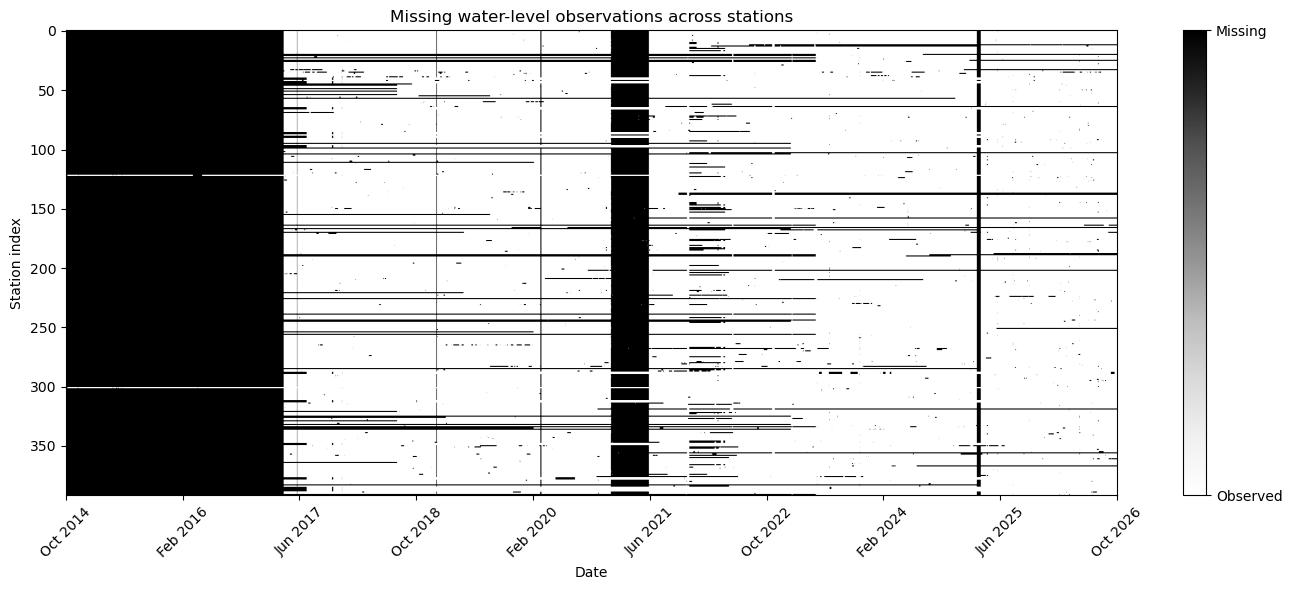

In [110]:
# Investigating the missing observations across different stations

# Select date columns
date_cols = df_avg.columns[3:]

data = df_avg[date_cols].apply(pd.to_numeric, errors="coerce")  # Make sure that the data has numerical values or NaN for missing values

# Convert columns to dates
data.columns = pd.to_datetime(date_cols, dayfirst=True)

# Insert missing dates
all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")

# If the date does NOT exist pandas creates a new column filled with NaN
data = data.reindex(columns=all_dates)

# Missing-data matrix: 1 = missing, 0 = observed
missing = data.isna().astype(int)

# Plot a heatmap
fig, ax = plt.subplots(figsize=(14, 6))

im = ax.imshow(missing, aspect="auto", cmap="Greys")

# Date labels
ticks = np.linspace(0, len(all_dates) - 1, 10, dtype=int)

# Set labels, ticks, and title
ax.set_xticks(ticks)
ax.set_xticklabels(all_dates[ticks].strftime("%b %Y"), rotation=45)

ax.set_xlabel("Date")
ax.set_ylabel("Station index")
ax.set_title("Missing water-level observations across stations")

# Colourbar
cbar = plt.colorbar(im, ax=ax)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Observed", "Missing"])

plt.tight_layout()
plt.show()

We also identified a number of abnormal values in our datasets, such as recorded river levels exceeding 100 m or falling below −100 m, which are unlikely to represent genuine observations. These could correspond to an alternative way of encoding missing data (sometimes encoded as numerical values such as 999 or −100 [[2]](#ref2)), human error or faulty measuring equipment. Another possible explanation is the occurrence of flood events, during which the measuring equipment may record erroneous values. To account for this, we decided to replace all observations with an absolute value greater than 36 m with NaN. The choice of this threshold aims to distinguish between unusually large values arising from alternative encodings of missing data and extreme but plausible water levels associated with genuine flood events.

We additionally note that only 12 stations in our dataset have tidal observations, which might be a useful gauge when analysing the clusteirng solution. One might expect a good clustering algorithm to be able to separate tidal stations from non-tidal ones. We decide to keep missing values as NaN instead of artificially imputing them. We considered interpolating when we have a 1 day gap, but given that water levels can fluctuate considerably over short timescales, interpolation might conceal genuine extreme events or introduce artificial patterns into the data. Therefore, in the end decided that this might cloud our analysis and chose to preserve missing values. All of our data preprocessing steps are contained within the data_prepare function, where we also transpose our DataFrames so that dates form the row index, facilitating time-series analysis using the built-in functionality of pandas [[3]](#ref3). We also verified that missing observations are consistent across the maximum, minimum and average water-level datasets.

In [121]:
results = []

for name, df in {
    "Average": df_avg,
    "Maximum": df_max,
    "Minimum": df_min
}.items():

    data = df.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

    n_outliers = (data.abs() > 30).sum().sum()
    n_observations = data.count().sum()

    results.append({
        "Dataset": name,
        "Observations": n_observations,
        "Abnormal observations": n_outliers,
        "Percentage (%)": 100 * n_outliers / n_observations
    })

display(pd.DataFrame(results).round(4).set_index("Dataset"))

# Frequency of abnormal values in the average dataset
data = df_avg.iloc[:, 3:].apply(pd.to_numeric, errors="coerce")

display(
    data.where(data.abs() > 36).stack().value_counts()
    .rename_axis("Abnormal value")
    .to_frame("Frequency")
)

,Observations,Abnormal observations,Percentage (%)
Dataset,,,
Average,1190691,929,0.0780
Maximum,1190691,979,0.0822
Minimum,1190691,759,0.0637


,Frequency
Abnormal value,
98.070,1
-10413.834,1
118645.205,1
76923.840,1
21739.828,1
...,...
20861.991,1
72943.521,1
20861.743,1


In [122]:
# Data preprocessing
def data_prepare(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(pd.to_numeric, errors="coerce")

    # Replace observations with |value| > 30 with NaN
    data = data.mask(data.abs() > 36)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(start=data.columns.min(), end=data.columns.max(), freq="D")

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = data_prepare(df_avg)
minimum = data_prepare(df_min)
maximum = data_prepare(df_max)

## Feature Engineering

The first step in building a model is to consider the features that will be used. We note that the clustering and classification tasks are significantly different and will therefore require different features to be considered. One of the main differences is that, while for clustering we use the entire dataset, for classification we use only the preceding seven days. It is therefore sensible to construct features based on the entire dataset for clustering, but features depending only on seven consecutive days for the classification task.

### Clustering

In the datasets, we are given monitoring stations and their respective mean, maximum and minimum water levels. Since these values depend on the characteristics of a specific river and the reference elevation of the station, they are not particularly well suited to the clustering problem, so we look for other possible measures.

One such measure that immediately comes to mind is the variability of the water level at each station. The simplest way to quantify this is to look at the range of the data (i.e. max − min). However, this measure is easily skewed by outliers. As an example, we can think of a river that has experienced only one flood event throughout the observation period. Using the range as a feature might result in this river being clustered together with rivers that exhibit consistently large water-level fluctuations, which would not be a desirable assignment. A similar problem arises when using the standard deviation. For this reason, we believe that the interquartile range (IQR) is a suitable measure in this case, since it is resistant to outliers and provides a more reliable measure of typical water-level variability.

Given that mitigating the risk of flooding is one of our main interests, we might also want to consider how extreme unusually high water levels are, which could help us identify stations susceptible to flooding. Conversely, we might also want to consider how extreme unusually low water levels are when investigating potential droughts.

We might also want to consider within-day variability and the magnitude of day-to-day changes. On a longer timescale, we can consider the autocorrelation between observations to understand whether water-level fluctuations occur predominantly over short or long timescales. We know that different seasons are characterised by different amounts of rainfall, so seasonality might also play an important role. Finally, we might want to introduce a feature that measures unusually large within-day fluctuations to distinguish between rivers with consistently large daily fluctuations and those with occasional but extreme ones.

As the next step, we investigate the correlation between the features to potentially disregard those that are highly correlated, as including several features that convey similar information might disproportionately influence our clustering algorithm. We can see that all measures of autocorrelation are highly correlated, so we decide to retain only the weekly autocorrelation, which provides the most distinct information relative to the other features.

Let $h_i(t)$ denote the average water level at station $i$ on day $t$, with $h_i^{\max}(t)$ and $h_i^{\min}(t)$ denoting the corresponding maximum and minimum water levels. We additionally denote by $Q_{p,i}$ the $p$-quantile of the average water-level observations at station $i$. Based on the considerations above, we construct the following features for each station. Note that when constructing the upper- and lower-tail intensity features, we normalise the distance between the corresponding extreme quantile and the median by the interquartile range. This allows us to quantify how extreme these observations are relative to the typical variability of water levels at each station. For instance, a water-level increase of 1 m might be relatively common for one river but highly unusual for another. By normalising with respect to the IQR, we aim to capture this distinction.

| Feature | Mathematical definition | Motivation |
|---|---|---|
| Interquartile range (IQR) | $Q_{0.75,i}-Q_{0.25,i}$ | Typical water-level variability |
| Upper-tail intensity | $\frac{Q_{0.99,i}-Q_{0.50,i}}{\mathrm{IQR}_i}$ | Relative extremity of high water levels |
| Lower-tail intensity | $\frac{Q_{0.50,i}-Q_{0.01,i}}{\mathrm{IQR}_i}$ | Relative extremity of low water levels |
| Within-day variability | $\operatorname{median}_t(h_i^{\max}(t)-h_i^{\min}(t))$ | Typical daily water-level fluctuations |
| Daily changes | $\operatorname{median}_t\lvert h_i(t)-h_i(t-1)\rvert$ | Typical day-to-day changes |
| Autocorrelation | $\operatorname{Corr}(h_i(t),h_i(t-k))$ | Temporal persistence over $k$ days |
| Seasonal variation | $\operatorname{median}_{\text{Jan–Jun}}h_i-\operatorname{median}_{\text{Jul–Dec}}h_i$ | Seasonal differences |

In [129]:
# Define the features we want to use for the clustering problem 

# Interquartile range
iqr = avg.quantile(0.75) - avg.quantile(0.25)

# Upper-tail intensity
tail = ((avg.quantile(0.99) - avg.quantile(0.50)) / iqr.where(iqr > 1e-8))

# Lower-tail intensity
tail_l = ((avg.quantile(0.50) - avg.quantile(0.01)) / iqr.where(iqr > 1e-8))

# Within-day variability (where to account for possible NaN values)
daily_range = (maximum - minimum).where(maximum >= minimum)
R = daily_range.median()

# Daily changes
D = avg.diff().abs().median()

# Daily qutocorrelation
A1 = avg.corrwith(avg.shift(1))

# 7. Seasonal variation
first_half = avg[avg.index.month.isin([1, 2, 3, 4, 5, 6])].median()
second_half = avg[avg.index.month.isin([7, 8, 9, 10, 11, 12])].median()

S = first_half - second_half

# Construct feature matrix
X_cluster = pd.DataFrame({
    "IQR": iqr,
    "Upper_tail": tail,
    "Daily_range": R,
    "Daily_change": D,
    "Autocorr_1": A1,
    "Seasonality": S,
    "Lower_tail": tail_l
})

### Classification

The classification task is substantially different in nature from the clustering task. The goal is to predict whether a flood will occur based on measurements from the preceding seven days. This raises several questions, such as how to deal with missing observations and what features to use. To deal with missing observations, we considered two approaches. The most obvious one is to simply remove all NaN values. The issue with this approach is that we lose temporal continuity and, at each step, would need to check the dates to ensure that we are considering consecutive days. Our alternative approach, and the one we adopt, is to maintain temporal continuity and identify valid eight-day periods. By a valid eight-day period, we mean eight consecutive days with no missing measurements, where the first seven days are used to construct the features and the eighth day determines the classification label. We find that every station has over 400 valid periods, with all but six stations having over 1,000. We deem this to be sufficient data to build a working model and proceed with this strategy.

Another important question is how to define a flood event. Since we are not given labels indicating when floods occurred, we need to introduce our own definition, which will naturally have some limitations. We expect flooding to be a rare event, characterised by exceptionally high water levels. For this reason, we decide to define a flood event as an observation exceeding the 99th percentile of the maximum water levels in the training dataset for each station. For each station $i$, we therefore define a threshold $q_i$ as the 99th percentile of its maximum water-level observations in the training dataset. The classification label for station $i$ on day $t$ is then defined as

$$
y_i(t)=
\begin{cases}
1, & h_i^{\max}(t)>q_i,\\
0, & h_i^{\max}(t)\leq q_i.
\end{cases}
$$

We split the data chronologically so that approximately 80% of valid observation periods are allocated to the training dataset and 20% to the test dataset. Following this split, we investigate the proportion of flood events in each dataset to ensure that a sufficient number of positive examples are available for both training and evaluation. We find that this split is suitable for this task, with the split occurring at index 2825. Importantly, we do not randomise the data, since we are dealing with time-series observations and want to assess the ability of our model to predict future events based on past observations.

Now that we have defined a flood event, assigned labels and split the data into training and test sets, it is time to consider what features to use. This is a highly non-trivial task, as it is not immediately clear which characteristics of the preceding seven days are most indicative of an upcoming flood event. We also note that flooding is influenced by a considerable degree of uncertainty, for instance due to sudden extreme rainfall, which cannot be anticipated from previous water-level observations alone. We therefore do not expect exceptionally high predictive performance. In fact, near-perfect predictions would warrant further investigation into potential data leakage, given the limited information available to the model.

The simplest idea is to consider the mean of the maximum water levels over the preceding seven days, which provides a measure of recent water levels while reducing the influence of individual daily fluctuations. This is the approach we initially use, and then try adding different features in order to tune the model. We provide a more detailed explanation of features used in the following sections.


In [133]:
# Check whether given observation is valid for each dataset
valid = avg.notna() & minimum.notna() & maximum.notna()

# Check for 8 consecutive valid days (valid means no NaN values within these days)
# (we need 7 days from which we predict plus the 8th day on which we predict)
valid_8 = valid.rolling(8, min_periods=8).sum().eq(8)

# Count valid windows for each station and sort from the least number of valid periods
counts = valid_8.sum().sort_values()

# Split approximately 80/20 based on valid windows
valid_period_sum = valid_8.sum(axis=1).cumsum() # Calculate how many total valid 8-day periods are at each date
split = (valid_period_sum >= 0.8 * counts.sum()).argmax() + 1 # Calculate the date at whcih the train/test split happens

# Define flood events as observations in the 99th percentile of the station's observations
thresholds = maximum.iloc[:split].quantile(0.99).dropna()

# Identify floods
flood = maximum[thresholds.index] > thresholds

# Keep only valid 8-day windows
valid_flood = flood.where(valid_8[thresholds.index])

# Split using row positions
y_train = valid_flood.iloc[:split].stack().astype(int)
y_test = valid_flood.iloc[split:].stack().astype(int)

print("Training samples:", len(y_train))
print("Test samples:", len(y_test))
print("Training flood percentage:", 100 * y_train.mean())
print("Test flood percentage:", 100 * y_test.mean())

Training samples: 932957
Test samples: 233205
Training flood percentage: 1.0220192356132167
Test flood percentage: 1.10803799232435


# Model Fitting and Tuning

## Clustering

During our analysis, we investigated two different clustering methods: K-means++ and hierarchical clustering. In clustering, we aim to minimise dissimilarity within clusters and maximise dissimilarity between different clusters. To assess how well this is achieved and determine an appropriate number of clusters, we investigate the silhouette score and within-cluster variation.

We found that both methods performed well in grouping together stations exhibiting tidal behaviour. While this was a very promising initial result, we also wanted to distinguish between different types of rivers with non-tidal observations. Hierarchical clustering yielded promising silhouette scores of above 0.6 for the three- and four-cluster solutions. However, upon further investigation, we found that this was achieved by constructing one disproportionately large cluster alongside several very small ones, which provided relatively little insight into the behaviour of most stations.

On the other hand, K-means++ achieved a considerably higher silhouette score for the two-cluster solution than for solutions with more clusters. While the elbow plot was not particularly insightful, the silhouette analysis clearly favoured the two-cluster solution. However, further investigation revealed that this solution primarily distinguishes between stations exhibiting tidal and non-tidal behaviour. Although this is an important finding and provides evidence that our clustering captures meaningful characteristics of the stations, given the relatively small number of tidal stations, we also wanted to explore different subcategories of non-tidal stations.

The three-cluster solution achieved a considerably low silhouette score of approximately 0.30, which was initially concerning. However, upon investigating the characteristics of the individual clusters, we found that they exhibited meaningfully different water-level behaviour. Considering the nature of the problem, there is no particular reason to expect Scottish rivers to fall into clearly separated categories. We therefore decided to proceed with the three-cluster K-means++ solution, which we believe provides a sensible compromise between statistical separation and physical interpretability. We also note that we standardise our features, since they are measured on different scales. Without standardisation, features with a larger numerical variability might disproportionately influence the distance between observations and hence the resulting clustering solution.

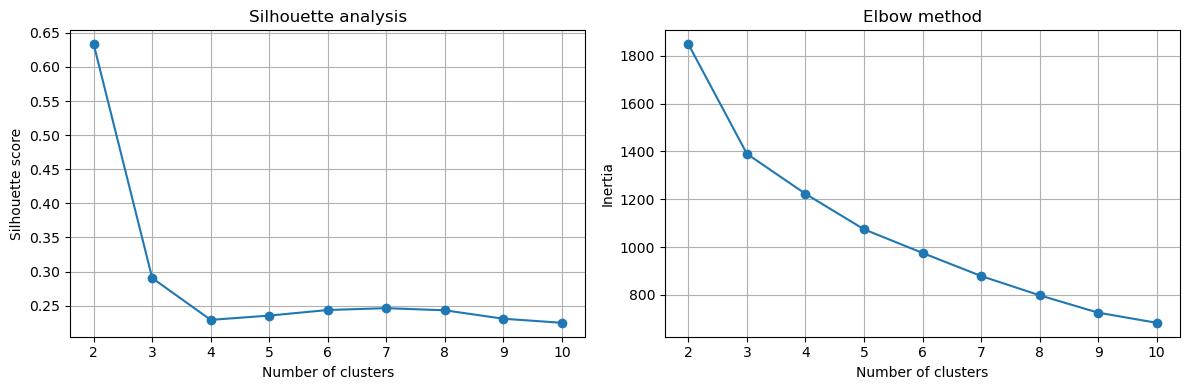

In [136]:
# Creating the pipeline and investigating the number of clusters

k_values = range(2, 11)

silhouette_scores = []
inertias = []

for k in k_values:

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("kmeans", KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            random_state=42
        ))
    ])

    labels = pipeline.fit_predict(X_cluster)

    X_scaled = pipeline.named_steps["scaler"].transform(X_cluster)

    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

    inertias.append(
        pipeline.named_steps["kmeans"].inertia_
    )


fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, silhouette_scores, marker="o")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Silhouette score")
axes[0].set_title("Silhouette analysis")

axes[1].plot(k_values, inertias, marker="o")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Inertia")
axes[1].set_title("Elbow method")

for ax in axes:
    ax.grid()

plt.tight_layout()
plt.show()

In [137]:
# Building a model with 3 clusters
pipeline3 = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=20,
        random_state=42
    ))
])

labels3 = pipeline3.fit_predict(X_cluster)

X_clustered3 = X_cluster.copy()
X_clustered3["Cluster"] = labels3

## Classification

We start the classification model by designing a baseline model to which we can compare our final model. Given that the data is highly imbalanced and flood events occur very rarely, a natural choice for a baseline model is a dummy classifier that always predicts no flood. Such a model will have incredible accuracy, but at a cost of 0 precision, recall and f1-score. This does not provide significant insight, so we instead choose as baseline a model that predicts whether a flood will happen or not only based on the previous day's max water level.

Additionally, we note that choosing appropriate features was the biggest challenge and the factor that had the greatest impact on the performance of our model. We considered various feature combinations, including the maximum water levels over the preceding seven days (7 features), the maximum, average and minimum water levels over the same period (21 features), as well as additional features accounting for seasonality and autocorrelation. After investigating different combinations, we found that the best results were obtained using a feature matrix consisting of six features for each station: the seven-day mean, the most recent maximum water level, the seven-day maximum, the seven-day range, the seven-day standard deviation and the square of the most recent maximum water level relative to the flood threshold.

Since the flood thresholds differ between stations, we express the water-level features relative to their respective station-specific thresholds. This allows us to compare observations from different stations in terms of their proximity to the flood threshold rather than their absolute water levels. The seven-day range and standard deviation, however, are left unchanged, as they already quantify water-level variability independently of absolute water levels. Finally, introducing the squared difference between the most recent maximum water level and the flood threshold allows us to account for a potentially nonlinear relationship between the most recent observation and the likelihood of flooding.

In [144]:
# Defining the feature matrix 
last = maximum.shift(1)

features = {
    "Mean_7d": maximum.shift(1).rolling(7).mean() - thresholds,
    "Last": maximum.shift(1) - thresholds,
    "Max_7d": maximum.shift(1).rolling(7).max() - thresholds, 
    "Range_7d": last.rolling(7).max() - last.rolling(7).min(),
    "Std_7d": last.rolling(7).std(),
    "Last_squared": (last - thresholds) ** 2
}


X = pd.concat(
    {name: df.stack() for name, df in features.items()},
    axis=1
).dropna()
X_train = X.loc[y_train.index]
X_test = X.loc[y_test.index]

# Building a baseline model

# Persistence baseline
y_pred_train_b = (X_train["Last"] > 0).astype(int)
y_pred_test_b = (X_test["Last"] > 0).astype(int)

[Paragraph about rejected model] We found that while Random forrest provided marginally better metrics, it was taking very long time to run, which is why it was rejected.

Our final chosen model was the logistic regression. We chose it following Oclam's razor law to always choose the simplest model if the preformance is similar. When tuning the model we considered different class_weight, different scalings and different C parameter. 

In [148]:
# Building final tuned model

logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight= "balanced",
        max_iter=1000,
        random_state=0,
        C = 1
    ))
])


# Train the model
logistic.fit(X_train, y_train)

# Make predictions
y_pred_train = logistic.predict(X_train)
y_pred_test = logistic.predict(X_test)

# Interpretation, Discussion & Conclusions

## Clustering
The final clustering solution consists of three clusters. The smallest cluster, Cluster 1, contains 10 of the 12 identified tidal observation stations, along with 10 non-tidal stations. In this cluster, we observe the largest median upper- and lower-tail intensities, as well as by far the largest within-day variability. These characteristics are consistent with the presence of tidal observations. An interesting avenue for further investigation is to explore the non-tidal stations assigned to this cluster, whose large within-day fluctuations might be associated with sudden high-water events, unrecorded tidal influences, or other hydrological characteristics.

The two remaining clusters distinguish predominantly non-tidal stations, with the most pronounced differences in IQR, upper-tail intensity, and seasonality.

Cluster 0 corresponds to stations exhibiting almost no seasonal variation and a relatively low median IQR. These stations are also characterised by small within-day fluctuations and day-to-day changes. We can therefore describe this cluster as representing relatively stable rivers with low typical water-level variability.

Cluster 2, on the other hand, exhibits a considerably stronger seasonal dependence, with higher water levels generally observed during the second half of the year. This is particularly interesting as it is consistent with seasonal rainfall patterns observed in parts of Scotland [[4]](#ref4). It is also characterised by a median IQR approximately twice as large as that of Cluster 0, alongside larger within-day fluctuations and day-to-day changes. We can therefore describe these rivers as naturally more variable and exhibiting more pronounced seasonal variations.

Interestingly, by comparing the upper-tail intensities, we find that the more stable rivers experience more extreme high-water events relative to their typical variability than the naturally more variable rivers. We might hypothesise that flood events represent a larger departure from the typical behaviour of stable rivers. In contrast, extreme observations in more variable rivers may be partly attributable to their naturally larger fluctuations. Further investigation is needed to determine whether these differences translate into differences in flood susceptibility.

Although our final clustering solution achieves a relatively low silhouette score of approximately 0.30, we believe that the identified clusters provide a meaningful interpretation of the data. The relatively weak separation may suggest that Scottish rivers vary continuously rather than falling into clearly defined categories. We should therefore interpret these clusters as groups of stations with broadly similar water-level behaviour, rather than as three fundamentally distinct river types.

From a river management perspective, our results suggest that different groups of monitoring stations might benefit from different monitoring strategies. For relatively stable rivers, unusually large departures from typical water levels might warrant particular attention. In contrast, for naturally more variable rivers, consider seasonal fluctuations when assessing exceptionally high water levels. Additionally, stations exhibiting tidal-like behaviour might benefit from more frequent monitoring to account for their considerably larger within-day fluctuations.



In [127]:
# Cluster sizes and median feature values
summary = X_clustered3.groupby("Cluster").median().round(3)
summary.insert(0, "Stations", X_clustered3.groupby("Cluster").size())

display(summary)

# Identify tidal stations
results = df_avg.loc[X_clustered3.index, ["Observation_ID"]].copy()

results["Cluster"] = X_clustered3["Cluster"]

results["Tidal"] = results["Observation_ID"].str.contains(
    "tidal-level", case=False, na=False
)

display(pd.crosstab(results["Cluster"], results["Tidal"]))

,Stations,IQR,Upper_tail,Daily_range,Daily_change,Autocorr_1,Seasonality,Lower_tail,R_extreme
Cluster,,,,,,,,,
0,231,0.188,3.408,0.026,0.016,0.835,-0.004,0.866,0.734
1,20,0.292,4.016,2.874,0.107,0.531,-0.064,3.962,4.653
2,141,0.375,2.716,0.070,0.045,0.819,-0.064,0.853,1.245


Tidal,False,True
Cluster,,
0,231,0
1,10,10
2,139,2


## Classification

First we note that the baseline model is characterised by very good accuracy, which is expected, since the flood event are very rare. On the other hand the precision, recall, and F1-score differ quite significantly between the train and test data, which reveals a potential limitation of relying only on the most recent observation when predicting floods. We note that recall is the metric of the percentage of how many true positives are detected, in our case, how many floods are detected. Therefore, this baseline model corrently detects 32% (for training data) and 47% (for test data) of actual flood event, and the precision metric being the same means that 32% (for training data) and 47%(for the test daya) of predicted flood events actually happened. These are promising results, however the fast that less than half of the flood events are being detected is worrying and it motivates more complex models.

In [146]:
# Evaluate baseline model performance
results = []

for name, y_true, y_pred in [
    ("Train", y_train, y_pred_train_b),
    ("Test", y_test, y_pred_test_b)
]:
    results.append({
        "Dataset": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0)
    })


display(pd.DataFrame(results).set_index("Dataset").round(4))

,Accuracy,Precision,Recall,F1-score
Dataset,,,,
Train,0.9861,0.3201,0.320,0.3200
Test,0.9882,0.4680,0.469,0.4685


We first investigate the effects of the individual features on the logistic regression model. We can see that the largest coefficient in absolute value corresponds to the `Last` feature, suggesting that the most recent water level relative to the flood threshold plays a particularly important role in predicting flood events.

Interestingly, the second largest coefficient in absolute value corresponds to the `Mean_7d` feature and is negative. While initially counterintuitive, this might suggest that, for a given most recent water level, a lower seven-day mean indicates a recent increase in water levels and hence a greater likelihood of flooding.

We also observe a positive coefficient for the seven-day range but a negative coefficient for the seven-day standard deviation. One possible explanation is that sudden changes in water levels are more indicative of imminent flooding than persistent fluctuations throughout the week. Finally, the inclusion of the squared `Last` feature allows the model to capture a nonlinear relationship between the most recent water level and the likelihood of flooding.

These results suggest that both the proximity to the flood threshold and recent changes in water levels are important factors to consider when forecasting flood events. However, given the correlations between our features, the individual coefficients should be interpreted with caution.

Last            2.263814
Mean_7d        -1.358066
Last_squared    0.941975
Range_7d        0.774664
Max_7d          0.709208
Std_7d         -0.458733
dtype: float64


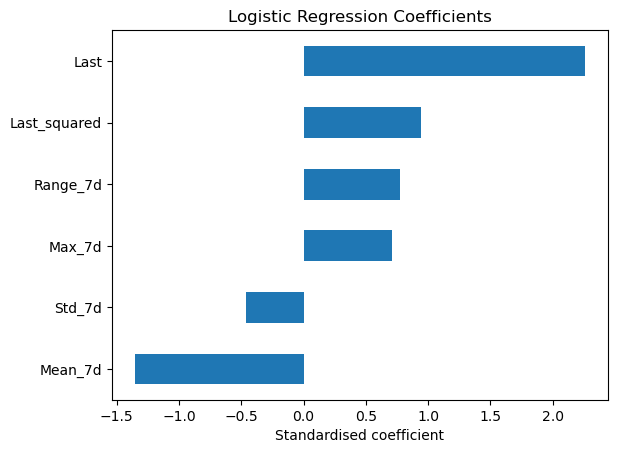

In [150]:
coef = pd.Series(
    logistic.named_steps["classifier"].coef_[0],
    index=X_train.columns
)
print(coef.sort_values(key=abs, ascending=False))

coef.sort_values().plot.barh()
plt.xlabel("Standardised coefficient")
plt.title("Logistic Regression Coefficients")
plt.show()

Finally, we investigate the performance metrics of our final fitted and tuned model. We can see that the accuracy has decreased compared to the baseline model, although it remains above 80%. More importantly, we have managed to increase recall substantially, with our model now correctly identifying between 70% and 80% of flood-labelled observations. This, however, comes at the cost of a considerable reduction in precision, which has dropped to approximately 5%.

Why, then, did we choose this model? Given the nature of the task, we believe that recall is of greater importance than precision, since failing to anticipate a flood event may have considerably more severe consequences than issuing a false alarm. While our model achieves significantly lower precision than the baseline, it is considerably better at detecting flood events.

Nevertheless, a precision of approximately 5% means that around 95% of predicted flood events constitute false alarms. In practice, this could place considerable strain on government and emergency services and undermine confidence in the forecasting system. While we believe that prioritising recall is justified in the context of flood forecasting, the low precision remains a significant limitation of our model. We would therefore recommend using the model as a preliminary indicator of potential flooding rather than as a standalone flood warning system.

In [152]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    ConfusionMatrixDisplay
)

for name, y_true, y_pred in [
    ("Train", y_train, y_pred_train),
    ("Test", y_test, y_pred_test)
]:
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_true, y_pred, zero_division=0))


Train
Accuracy: 0.8422403176137807
Precision: 0.045602197250795576
Recall: 0.7243838489774514
F1-score: 0.08580284104672758

Test
Accuracy: 0.8610921721232392
Precision: 0.06024665132471824
Recall: 0.7902476780185759
F1-score: 0.11195789242831296


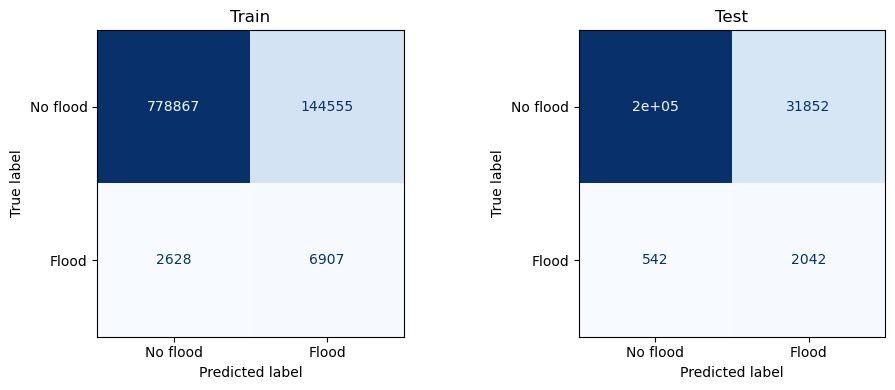

In [153]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, y_true, y_pred, title in zip(
    axes,
    [y_train, y_test],
    [y_pred_train, y_pred_test],
    ["Train", "Test"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred,
        labels=[0, 1],
        display_labels=["No flood", "Flood"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()

## Conclusion and limitations

In this report, we investigated the behaviour of Scottish rivers and the potential for predicting flood events using supervised and unsupervised machine learning techniques.

Our clustering analysis identified three groups of stations exhibiting distinct water-level characteristics: stations exhibiting tidal-like behaviour, relatively stable rivers and naturally more variable rivers with stronger seasonal dependence. These findings suggest that different groups of stations might benefit from different monitoring strategies, with particular attention paid to departures from typical water-level behaviour and seasonal fluctuations.

For the classification task, we found that the most recent water level relative to the flood threshold, alongside recent changes in water levels, plays an important role in predicting flood events. While our final logistic regression model substantially improves recall compared to the persistence baseline, its low precision limits its practical applicability. This suggests that historical water-level observations alone might not provide sufficient information for reliable flood forecasting.

One of the main limitations of our model is that it relies solely on historical river-level observations and has no access to additional information such as rainfall measurements, weather forecasts, snowmelt or soil saturation. Flood events caused by sudden and intense rainfall might therefore occur without any clear indication in the preceding seven days. Incorporating such information could potentially improve the precision of our model while maintaining high recall.

Another important limitation lies in our definition of a flood event. While using the 99th percentile of each station's maximum water levels in the training dataset provides a consistent definition across all 392 stations, exceeding this threshold does not necessarily imply that a river has breached its banks or caused damage to surrounding areas. Access to independently verified flood records would allow us to construct more reliable classification labels.

We also note that approximately 30.6% of the raw data was missing, including an extended period of considerable missingness in 2021, potentially associated with COVID-19. Additionally, observations with an absolute value exceeding 30 m were treated as missing. Our decision to disregard periods containing missing observations might introduce bias, particularly if extreme flood events themselves contribute to equipment failure or missing measurements.

Finally, our logistic regression model uses the same set of coefficients for all monitoring stations, despite our clustering analysis revealing considerable differences in their water-level behaviour. An interesting avenue for further investigation would therefore be to construct separate classification models for each of the identified clusters or incorporate cluster membership as an additional feature. This might allow us to better account for the different characteristics of individual rivers and achieve a better balance between detecting flood events and avoiding false alarms.

# Generative AI statement

Generative AI was used in this project in following ways:
- Told us how to make citable references in Jupyter Notebook
- Debug code and help with error messages
- Suggest code improvements, and ways to make it cleaner and faster
- Improve the presentation of the plots 
- Grammer check and rewording suggestions 
- Turn the code outputs into neat tables 

# References

<a id="ref1"></a>
[1] Scottish Government (2026). 
*National Flood Resilience Strategy: Implementation Plan*.
[Available online](https://www.gov.scot/publications/national-flood-resilience-strategy-implementation-plan/pages/2/).

<a id="ref2"></a>
[2] Sell, T. (2026). *Machine Learning in Python: 
Week 1 – Introduction to Machine Learning and Feature Engineering*. 
Lecture notes, School of Mathematics, University of Edinburgh.

<a id="ref3"></a>
[3] pandas development team (n.d.). 
*Time series / date functionality*. pandas documentation.
[Available online](https://pandas.pydata.org/docs/user_guide/timeseries.html).
(Accessed: 24 November 2026).

<a id="ref4"></a>
[4] Met Office (n.d.). *Charterhall: Location-specific long-term 
averages (1991–2020)*. 
[Available online](https://www.metoffice.gov.uk/research/climate/maps-and-data/location-specific-long-term-averages/gcykcv8b2).
(Accessed: 25 November 2026).